# Data Inspection

## 1. Load the datasets

Load training, later, and holdout datasets. The holdout feature file is expected to lack the target column.

In [1]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"

train = pd.read_csv(DATA_DIR / "train.csv")
later = pd.read_csv(DATA_DIR / "later.csv")
holdout = pd.read_csv(DATA_DIR / "holdout_features.csv")

print("Train shape:", train.shape)
print("Later shape:", later.shape)
print("Holdout shape:", holdout.shape)

Train shape: (1030, 11)
Later shape: (300, 11)
Holdout shape: (250, 10)


## 2. Basic inspection

Inspect a sample, dimensions, and columns for each dataset to understand their structure.

In [2]:
print("\nTRAIN DATASET")
print(train.head())
print("Shape:", train.shape)
print("Columns:", train.columns.tolist())

print("\nLATER DATASET")
print(later.head())
print("Shape:", later.shape)
print("Columns:", later.columns.tolist())

print("\nHOLDOUT DATASET")
print(holdout.head())
print("Shape:", holdout.shape)
print("Columns:", holdout.columns.tolist())


TRAIN DATASET
  record_id        date  students_on_campus  menu_price_rs  temp_c  \
0    R00001  2026-01-01                2120             54    17.0   
1    R00002  2026-01-01                4167            120    38.6   
2    R00003  2026-01-01                4301            116    43.4   
3    R00004  2026-01-01                4446             31    32.2   
4    R00005  2026-01-01                2257             73    18.1   

   exam_days_left  special_dishes  queue_minutes_yesterday  day_type    block  \
0              16               5                     24.6   holiday   Hostel   
1              58               3                     27.5   weekday   Hostel   
2              24               3                      6.1  Saturday   Hostel   
3               0               5                     33.8   weekday  A-Block   
4              24               1                   2070.0   holiday  B-Block   

   plates_sold  
0          459  
1          258  
2          263  
3        

## 3. Types, missingness, duplicates, and statistics

These are baseline checks on the training dataset. Duplicate counts here are exact full-row duplicates.

In [3]:
print("\nDATA TYPES")
print(train.dtypes)

print("\nMISSING VALUES")
print(train.isnull().sum())

print("\nDUPLICATE ROWS")
print(train.duplicated().sum())

print("\nSTATISTICAL SUMMARY")
print(train.describe().to_string())


DATA TYPES
record_id                      str
date                           str
students_on_campus           int64
menu_price_rs                int64
temp_c                     float64
exam_days_left               int64
special_dishes               int64
queue_minutes_yesterday    float64
day_type                       str
block                          str
plates_sold                  int64
dtype: object

MISSING VALUES
record_id                  0
date                       0
students_on_campus         0
menu_price_rs              0
temp_c                     0
exam_days_left             0
special_dishes             0
queue_minutes_yesterday    0
day_type                   0
block                      0
plates_sold                0
dtype: int64

DUPLICATE ROWS
30

STATISTICAL SUMMARY
       students_on_campus  menu_price_rs       temp_c  exam_days_left  special_dishes  queue_minutes_yesterday  plates_sold
count         1030.000000    1030.000000  1030.000000     1030.000000     103

## 4. Categorical distributions and column-availability leakage check

Compare training-only feature columns against holdout columns, excluding the target. This only checks column availability; it cannot detect every form of target leakage.

In [4]:
print("\nDAY TYPE VALUES")
print(train["day_type"].value_counts())

print("\nBLOCK VALUES")
print(train["block"].value_counts())

print("\nEXTRA TRAINING COLUMNS")
print(set(train.columns) - set(holdout.columns) - {"plates_sold"})

# 1. Check for data leakage
print("\n1. DATA LEAKAGE")
print(set(train.columns) - set(holdout.columns) - {"plates_sold"})


DAY TYPE VALUES
day_type
weekday      364
holiday      306
saturday     207
HOLIDAY       13
 saturday     13
 weekday      13
wee.          13
Holiday       12
hol.          12
Weekday       12
sat.          11
WEEKDAY       11
 holiday       9
SATURDAY       9
Saturday       8
saturday       6
weekday        6
holiday        5
Name: count, dtype: int64

BLOCK VALUES
block
B-Block    358
Hostel     357
A-Block    315
Name: count, dtype: int64

EXTRA TRAINING COLUMNS
set()

1. DATA LEAKAGE
set()


## 5. Check for a unit mix-up

Summarize `queue_minutes_yesterday` by block for both train and later datasets. Compare distributions and investigate whether one block appears to use a different unit.

In [5]:
print("\n2. UNIT MIX-UP")
print(train.groupby("block")["queue_minutes_yesterday"].describe())
print(later.groupby("block")["queue_minutes_yesterday"].describe())


2. UNIT MIX-UP
         count         mean         std    min    25%     50%     75%     max
block                                                                        
A-Block  315.0    21.343492   11.034075    2.1   11.6    21.3    31.4    39.9
B-Block  358.0  1280.782123  642.624688  132.0  757.5  1263.0  1842.0  2400.0
Hostel   357.0    20.740056   10.987930    2.1   11.1    20.7    30.0    39.9
         count       mean        std  min     25%   50%    75%   max
block                                                               
A-Block   93.0  19.908602  11.094629  2.3  11.100  17.6  29.60  39.9
B-Block  116.0  19.127586  11.270273  2.0   9.125  18.4  28.70  40.0
Hostel    91.0  21.419780  10.738262  2.1  10.750  22.8  30.15  39.9


## 6. Check sentinel values

Count the suspicious temperature value `999`. Do not replace it in this notebook; cleaning happens in the cleaning stage.

In [6]:
print("\n3. SENTINEL VALUES")
print("Temperature 999 count:", (train["temp_c"] == 999).sum())


3. SENTINEL VALUES
Temperature 999 count: 34


## 7. Duplicate rows

Count exact duplicate records. This is a full-row comparison, not a key-based duplicate check.

In [7]:
print("\n4. DUPLICATE ROWS")
print("Duplicate count:", train.duplicated().sum())


4. DUPLICATE ROWS
Duplicate count: 30


## 8. Repeated-value investigation (initial scan)

For numeric columns, show the five most frequent values. High frequency alone does not prove a sensor is stuck; it is an investigation signal.

In [8]:
print("\n5. STUCK SENSOR")

for col in train.select_dtypes(include="number").columns:
    print("\nColumn:", col)
    print(train[col].value_counts().head(5))


5. STUCK SENSOR

Column: students_on_campus
students_on_campus
3380    4
4783    3
3729    3
1269    3
5290    3
Name: count, dtype: int64

Column: menu_price_rs
menu_price_rs
109    25
69     22
108    19
38     17
36     17
Name: count, dtype: int64

Column: temp_c
temp_c
999.0    34
18.1      8
41.5      8
14.2      7
10.3      7
Name: count, dtype: int64

Column: exam_days_left
exam_days_left
1     25
15    25
28    25
24    23
59    22
Name: count, dtype: int64

Column: special_dishes
special_dishes
1    181
2    174
3    173
4    169
5    159
Name: count, dtype: int64

Column: queue_minutes_yesterday
queue_minutes_yesterday
10.9    8
38.0    7
36.9    7
38.7    6
22.9    6
Name: count, dtype: int64

Column: plates_sold
plates_sold
395    10
453    10
412     9
415     9
417     9
Name: count, dtype: int64


## 9. Target outlier / typo investigation

Inspect the largest `plates_sold` values and the later target summary. Large values are candidates for review, not automatically confirmed typos.

In [9]:
print("\n6. TARGET TYPOS")
print(train["plates_sold"].sort_values(ascending=False).head(40).to_string())

print("\nLater target statistics")
print(later["plates_sold"].describe())


6. TARGET TYPOS
69     5260
371    4920
273    4810
676    4510
769    4510
398    4120
831    4040
140    4020
274    3790
509    3720
508    3720
695    3280
248    3130
666    2470
114    2220
744    1940
80      610
444     593
158     584
638     581
629     574
399     572
832     566
902     561
185     556
566     555
724     555
370     552
178     551
786     550
8       549
557     549
576     548
393     546
157     546
235     545
872     544
13      544
145     541
652     538

Later target statistics
count    300.000000
mean     277.013333
std      128.095020
min        0.000000
25%      176.500000
50%      274.500000
75%      363.250000
max      602.000000
Name: plates_sold, dtype: float64


## 10. Spelling variants

List unique values in `day_type` to identify inconsistent category spelling/casing.

In [10]:
print("\n7. SPELLING VARIANTS")
print(train["day_type"].unique())
print(later["day_type"].unique())


7. SPELLING VARIANTS
<StringArray>
[  'holiday',   'weekday',  'Saturday',  'saturday',   'Holiday',      'sat.',
  'holiday ',  ' holiday',   'HOLIDAY',      'hol.', ' saturday',  ' weekday',
   'WEEKDAY', 'saturday ',      'wee.',  'weekday ',   'Weekday',  'SATURDAY']
Length: 18, dtype: str
<StringArray>
['weekday', 'saturday', 'holiday']
Length: 3, dtype: str


## 11. Consecutive repeated readings after temporarily removing duplicates

Remove exact duplicates for this analysis, sort by date and record ID, then group runs of consecutive identical values. This ranks runs by row count; it is a candidate sensor-stuck check, not a definitive diagnosis. Note: numeric identifiers may also appear in this loop and should be excluded from sensor interpretation.

In [11]:
check = train.drop_duplicates().sort_values(["date", "record_id"])

print("\nSTUCK SENSOR INVESTIGATION")

for col in check.select_dtypes(include="number").columns:
    groups = check[col].ne(check[col].shift()).cumsum()
    runs = check.groupby(groups).agg(
        value=(col, "first"),
        count=(col, "size"),
        start_date=("date", "min"),
        end_date=("date", "max")
    )
    print("\nColumn:", col)
    print(runs.sort_values("count", ascending=False).head(3))


STUCK SENSOR INVESTIGATION

Column: students_on_campus
                    value  count  start_date    end_date
students_on_campus                                      
1                    2120      1  2026-01-01  2026-01-01
672                  5569      1  2026-05-05  2026-05-05
659                  2571      1  2026-05-03  2026-05-03

Column: menu_price_rs
               value  count  start_date    end_date
menu_price_rs                                      
909              108      2  2026-06-17  2026-06-17
395               79      2  2026-03-17  2026-03-17
958               43      2  2026-06-24  2026-06-24

Column: temp_c
        value  count  start_date    end_date
temp_c                                      
777      33.2      2  2026-05-26  2026-05-26
898      26.7      2  2026-06-14  2026-06-14
116      13.4      2  2026-01-21  2026-01-21

Column: exam_days_left
                value  count  start_date    end_date
exam_days_left                                      
189  

## 12. Verify the B-Block queue conversion hypothesis

Temporarily divide B-Block queue readings by 60 and summarize. This is only a plausibility check; the conversion must be justified by the observed distributions and problem statement.

In [12]:
print("\nCORRECTED B-BLOCK QUEUE")

queue = check.loc[
    check["block"] == "B-Block",
    "queue_minutes_yesterday"
]

print((queue / 60).describe())


CORRECTED B-BLOCK QUEUE
count    347.000000
mean      21.435735
std       10.797559
min        2.200000
25%       12.550000
50%       21.100000
75%       30.750000
max       40.000000
Name: queue_minutes_yesterday, dtype: float64


## 13. Final counts after exact duplicate removal

Recount sentinel values and target values over 1000 after duplicate removal, and report the remaining row count.

In [13]:
print("\nFINAL COUNTS")
print("Sentinel values:", (check["temp_c"] == 999).sum())
print("Target typos:", (check["plates_sold"] > 1000).sum())
print("Remaining rows:", len(check))


FINAL COUNTS
Sentinel values: 34
Target typos: 15
Remaining rows: 1000


## 14. Repeated readings by block

Find the longest repeated run for each numeric column within each block. Interpret results carefully: the algorithm ranks by consecutive row count, and includes numeric columns such as IDs unless excluded.

In [14]:
print("\nFINAL STUCK SENSOR CHECK")

for block, group in check.groupby("block"):
    print("\nBlock:", block)
    for col in check.select_dtypes(include="number").columns:
        runs = group[col].ne(group[col].shift()).cumsum()
        result = group.groupby(runs).agg(
            value=(col, "first"),
            count=(col, "size"),
            start_date=("date", "min"),
            end_date=("date", "max")
        )
        print(col)
        print(result.nlargest(1, "count").to_string())


FINAL STUCK SENSOR CHECK

Block: A-Block
students_on_campus
                    value  count  start_date    end_date
students_on_campus                                      
1                    4446      1  2026-01-01  2026-01-01
menu_price_rs
               value  count  start_date    end_date
menu_price_rs                                      
32                69      2  2026-01-17  2026-01-18
temp_c
        value  count  start_date    end_date
temp_c                                      
1        32.2      1  2026-01-01  2026-01-01
exam_days_left
                value  count  start_date    end_date
exam_days_left                                      
121                 6      2  2026-03-11  2026-03-11
special_dishes
                value  count  start_date    end_date
special_dishes                                      
12                  3      3  2026-01-07  2026-01-07
queue_minutes_yesterday
                         value  count  start_date    end_date
queue_minutes_yesterda

In [15]:
# Compact stuck-sensor investigation

check = train.drop_duplicates().copy()
check["date"] = pd.to_datetime(check["date"])
check = check.sort_values(["date", "record_id"])

sensor_columns = check.select_dtypes(include="number").columns.drop(
    "record_id", errors="ignore"
)

suspect_runs = []

for block, group in check.groupby("block"):
    group = group.sort_values(["date", "record_id"])

    for col in sensor_columns:
        run_id = group[col].ne(group[col].shift()).cumsum()

        runs = group.groupby(run_id).agg(
            value=(col, "first"),
            count=(col, "size"),
            start_date=("date", "min"),
            end_date=("date", "max")
        )

        runs["block"] = block
        runs["column"] = col

        suspect_runs.append(runs.reset_index(drop=True))

all_runs = pd.concat(suspect_runs, ignore_index=True)

# Longest repeated runs first
all_runs = all_runs.sort_values(
    ["count", "start_date"],
    ascending=[False, True]
)

# Show only repeated runs of at least 4 consecutive records
suspicious = all_runs[all_runs["count"] >= 4]

print("Repeated runs >= 4 consecutive rows:")
display(suspicious)

Repeated runs >= 4 consecutive rows:


,value,count,start_date,end_date,block,column
5973,2.0,4,2026-03-22,2026-03-24,Hostel,special_dishes
3650,5.0,4,2026-04-25,2026-04-26,B-Block,special_dishes


In [16]:
# Restrict the stuck-sensor investigation to sensor-like features

sensor_columns = [
    col for col in check.select_dtypes(include="number").columns
    if any(keyword in col.lower() for keyword in [
        "temp", "humidity", "rain", "wind"
    ])
]

print("Sensor columns being investigated:", sensor_columns)

Sensor columns being investigated: ['temp_c']


In [17]:
sensor_runs = []

for block, group in check.groupby("block"):
    group = group.sort_values(["date", "record_id"])

    for col in sensor_columns:
        run_id = group[col].ne(group[col].shift()).cumsum()

        runs = group.groupby(run_id).agg(
            value=(col, "first"),
            count=(col, "size"),
            start_date=("date", "min"),
            end_date=("date", "max")
        )

        runs["block"] = block
        runs["column"] = col

        sensor_runs.append(runs.reset_index(drop=True))

sensor_results = pd.concat(sensor_runs, ignore_index=True)

suspicious_sensors = sensor_results[
    sensor_results["count"] >= 4
].sort_values("count", ascending=False)

display(suspicious_sensors)

,value,count,start_date,end_date,block,column


In [18]:
# Investigate queue-time values across blocks

queue_col = "queue_minutes_yesterday"

print("Queue-time statistics by block:\n")

display(
    train.groupby("block")[queue_col]
    .describe()
    .round(2)
)

Queue-time statistics by block:



,count,mean,std,min,25%,50%,75%,max
block,,,,,,,,
A-Block,315.0,21.34,11.03,2.1,11.6,21.3,31.4,39.9
B-Block,358.0,1280.78,642.62,132.0,757.5,1263.0,1842.0,2400.0
Hostel,357.0,20.74,10.99,2.1,11.1,20.7,30.0,39.9


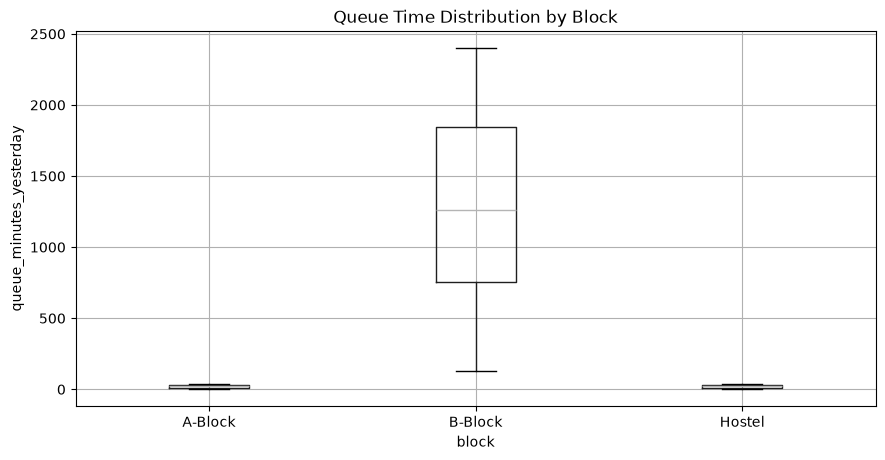

In [19]:
import matplotlib.pyplot as plt

train.boxplot(
    column="queue_minutes_yesterday",
    by="block",
    figsize=(10, 5)
)

plt.title("Queue Time Distribution by Block")
plt.suptitle("")
plt.ylabel("queue_minutes_yesterday")
plt.xticks(rotation=0)
plt.show()

In [20]:
# Test the proposed B-Block conversion without modifying the original dataset

queue_col = "queue_minutes_yesterday"

queue_corrected = train.copy()

queue_corrected.loc[
    queue_corrected["block"] == "B-Block",
    queue_col
] /= 60

print("BEFORE correction:")
display(train.groupby("block")[queue_col].describe().round(2))

print("\nAFTER correction:")
display(queue_corrected.groupby("block")[queue_col].describe().round(2))

BEFORE correction:


,count,mean,std,min,25%,50%,75%,max
block,,,,,,,,
A-Block,315.0,21.34,11.03,2.1,11.6,21.3,31.4,39.9
B-Block,358.0,1280.78,642.62,132.0,757.5,1263.0,1842.0,2400.0
Hostel,357.0,20.74,10.99,2.1,11.1,20.7,30.0,39.9



AFTER correction:


,count,mean,std,min,25%,50%,75%,max
block,,,,,,,,
A-Block,315.0,21.34,11.03,2.1,11.60,21.30,31.4,39.9
B-Block,358.0,21.35,10.71,2.2,12.62,21.05,30.7,40.0
Hostel,357.0,20.74,10.99,2.1,11.10,20.70,30.0,39.9


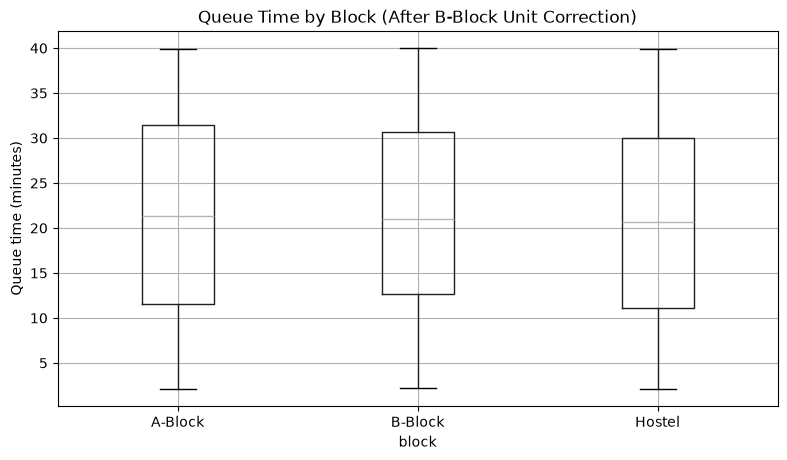

In [21]:
import matplotlib.pyplot as plt

queue_corrected.boxplot(
    column=queue_col,
    by="block",
    figsize=(9, 5)
)

plt.title("Queue Time by Block (After B-Block Unit Correction)")
plt.suptitle("")
plt.ylabel("Queue time (minutes)")
plt.show()

### Finding: B-Block Queue-Time Unit Inconsistency

**Problem identified:** The `queue_minutes_yesterday` feature in B-Block contains values substantially larger than those in A-Block and Hostel.

**Evidence:** Before correction, B-Block's median was 1263 and its mean was 1280.78, while A-Block and Hostel had medians of 21.3 and 20.7. B-Block's values were approximately 60 times higher.

**Hypothesis:** B-Block queue times were recorded in seconds rather than minutes.

**Validation:** Dividing B-Block values by 60 resulted in a mean of 21.35, median of 21.05, minimum of 2.2, and maximum of 40.0. These statistics closely align with A-Block and Hostel.

**Conclusion:** The evidence strongly supports a seconds-to-minutes unit inconsistency in B-Block. A conversion by 60 is justified.

**Action:** Apply the conversion during the data-cleaning stage, not during the original data investigation. The original raw dataset remains unchanged.